# LAB 05: HOG-Based Industrial Defect Detection and Classification

**Pipeline:** Image → Preprocessing → HOG Feature Extraction → ML Classifier → Defective / Non-Defective decision

**Dataset:** NEU Steel Surface Defect (train/valid split) from Kaggle, downloaded automatically with `kagglehub`.

> **Important note about the dataset:** NEU-DET contains 6 defect classes only (crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches). It has **no "normal" images**.
> For the binary task, this notebook builds:
> * **Class 1 (Defective):** a crop centred on an annotated defect bounding box
> * **Class 0 (Non-defective):** a crop from the same steel surface that does **not** overlap any annotated box
>
> Train / validation / test splits are made **by image**, so crops from one image never appear in two splits (no leakage).
> The multi-class (6 defect types) task is done at the end as the advanced part.

## 0. Setup

In [1]:
!pip install -q kagglehub scikit-image scikit-learn opencv-python-headless matplotlib seaborn pandas joblib

In [2]:
import os, glob, random, time, warnings
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd
import cv2, matplotlib.pyplot as plt, seaborn as sns, joblib
from joblib import Parallel, delayed
from skimage.feature import hog
from skimage import exposure
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

IMG_SIZE = 96      # common resolution used for HOG (binary task)
CROP     = 100     # crop size taken from the 200x200 original images
DEF_CELL, DEF_ORI = 8, 9   # default HOG parameters

## 1. Load and inspect the dataset (Task 1)

In [3]:
import kagglehub
DATASET  = "sovitrath/neu-steel-surface-defect-detect-trainvalid-split"

# Download the dataset (the files are cached after the first time)
DATA_DIR = kagglehub.dataset_download(DATASET)
print("Dataset path:", DATA_DIR)
# If you get a 403 error, run kagglehub.login() once and try again.

img_paths = sorted(p for e in ("jpg", "jpeg", "png", "bmp")
                   for p in glob.glob(os.path.join(DATA_DIR, "**", f"*.{e}"), recursive=True))
xml_map = {os.path.splitext(os.path.basename(p))[0]: p
           for p in glob.glob(os.path.join(DATA_DIR, "**", "*.xml"), recursive=True)}

def class_of(p):
    stem = os.path.splitext(os.path.basename(p))[0]
    head, _, tail = stem.rpartition("_")
    return head if tail.isdigit() and head else os.path.basename(os.path.dirname(p))

def split_folder(p):
    parts = [x.lower() for x in p.split(os.sep)]
    return "train" if "train" in parts else ("valid" if ("valid" in parts or "val" in parts) else "other")

df = pd.DataFrame({"path": img_paths})
df["class"]  = df.path.map(class_of)
df["folder"] = df.path.map(split_folder)
df["has_xml"] = df.path.map(lambda p: os.path.splitext(os.path.basename(p))[0] in xml_map)
print("Total images:", len(df), "| with XML annotations:", int(df.has_xml.sum()))
display(pd.crosstab(df["class"], df["folder"], margins=True))

sample = cv2.imread(df.path.iloc[0])
print("Example image shape:", sample.shape, "dtype:", sample.dtype)

Using Colab cache for faster access to the 'neu-steel-surface-defect-detect-trainvalid-split' dataset.
Dataset path: /kaggle/input/neu-steel-surface-defect-detect-trainvalid-split
Total images: 1800 | with XML annotations: 1800


folder,other,All
class,,
crazing,300,300
inclusion,300,300
patches,300,300
pitted_surface,300,300
rolled-in_scale,300,300
scratches,300,300
All,1800,1800


Example image shape: (200, 200, 3) dtype: uint8


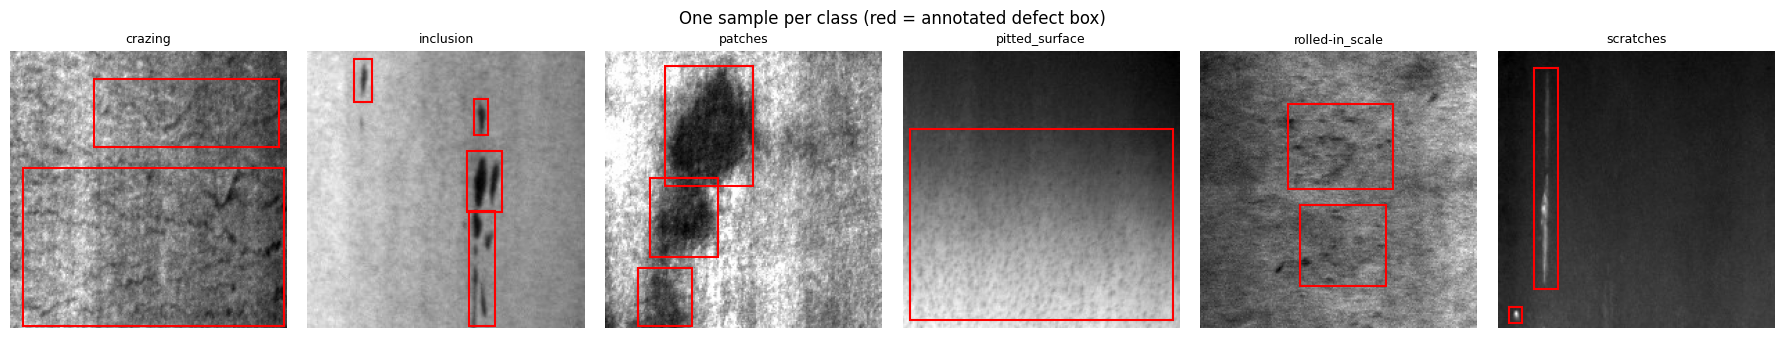

In [4]:
def read_boxes(p):
    x = xml_map.get(os.path.splitext(os.path.basename(p))[0])
    boxes = []
    if x:
        for o in ET.parse(x).getroot().iter("object"):
            b = o.find("bndbox")
            boxes.append(tuple(int(float(b.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax")))
    return boxes

classes = sorted(df["class"].unique())
fig, axs = plt.subplots(1, len(classes), figsize=(3 * len(classes), 3.4))
for ax, c in zip(np.atleast_1d(axs), classes):
    p = df[df["class"] == c].path.iloc[0]
    ax.imshow(cv2.imread(p, cv2.IMREAD_GRAYSCALE), cmap="gray")
    for (x0, y0, x1, y1) in read_boxes(p):
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red", lw=1.5))
    ax.set_title(c, fontsize=9); ax.axis("off")
plt.suptitle("One sample per class (red = annotated defect box)"); plt.tight_layout(); plt.show()

## 2. Split by image, resize and grayscale (Tasks 2 & 3)
The split is done **per image** (70 % train, 15 % validation, 15 % test) and stratified by defect type.

In [5]:
assert df.has_xml.sum() > 0, "No XML annotations found: binary normal-crop generation needs bounding boxes."
d = df[df.has_xml].reset_index(drop=True)
lab = dict(zip(d.path, d["class"]))

p_trval, p_test = train_test_split(d.path.values, test_size=0.15, stratify=d["class"], random_state=SEED)
p_train, p_val  = train_test_split(p_trval, test_size=0.1765,
                                  stratify=[lab[p] for p in p_trval], random_state=SEED)
print(f"images -> train {len(p_train)} | val {len(p_val)} | test {len(p_test)}")

def load_gray(p):
    bgr = cv2.imread(p, cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                     # Task 3: grayscale

def prep(g, size=IMG_SIZE):
    return cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)  # Task 2: common resolution

def overlap_frac(win, b):
    ix = max(0, min(win[2], b[2]) - max(win[0], b[0]))
    iy = max(0, min(win[3], b[3]) - max(win[1], b[1]))
    return ix * iy / ((win[2] - win[0]) * (win[3] - win[1]))

def make_binary_samples(paths, seed):
    rng = np.random.default_rng(seed)
    X, y, cls = [], [], []
    for p in paths:
        g = load_gray(p); H, W = g.shape; c = min(CROP, H, W)
        boxes = read_boxes(p)
        if not boxes:
            continue
        # defective crop: centred on a random annotated box
        b = boxes[rng.integers(len(boxes))]
        cx, cy = (b[0] + b[2]) // 2, (b[1] + b[3]) // 2
        x0 = int(np.clip(cx - c // 2, 0, W - c)); y0 = int(np.clip(cy - c // 2, 0, H - c))
        X.append(prep(g[y0:y0 + c, x0:x0 + c])); y.append(1); cls.append(lab[p])
        # normal crop: window that does not overlap any annotated box
        for _ in range(80):
            x0 = int(rng.integers(0, W - c + 1)); y0 = int(rng.integers(0, H - c + 1))
            if all(overlap_frac((x0, y0, x0 + c, y0 + c), bb) < 0.02 for bb in boxes):
                X.append(prep(g[y0:y0 + c, x0:x0 + c])); y.append(0); cls.append("normal")
                break
    return np.array(X, np.uint8), np.array(y), np.array(cls)

Xtr_img, ytr, ctr = make_binary_samples(p_train, SEED)
Xva_img, yva, cva = make_binary_samples(p_val,   SEED + 1)
Xte_img, yte, cte = make_binary_samples(p_test,  SEED + 2)
for n, y in [("train", ytr), ("val", yva), ("test", yte)]:
    print(f"{n:5s}: normal={np.sum(y == 0):4d}  defective={np.sum(y == 1):4d}")
if np.sum(ytr == 0) < 50:
    print("WARNING: very few normal crops were found. Lower the overlap threshold or CROP size.")

images -> train 1259 | val 271 | test 270
train: normal= 368  defective=1259
val  : normal=  88  defective= 271
test : normal=  87  defective= 270


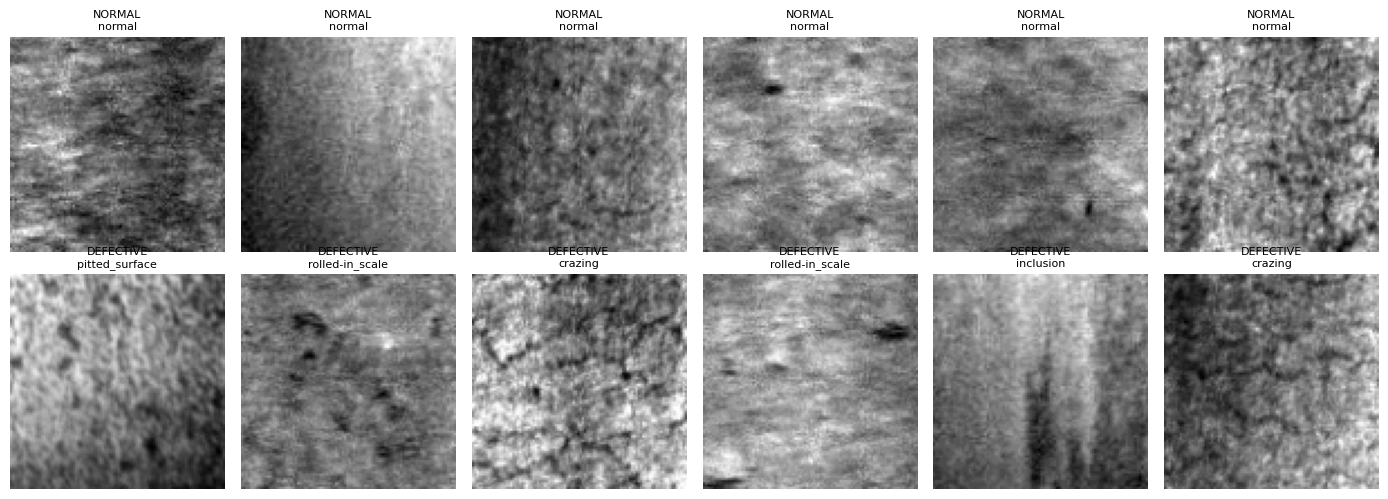

In [6]:
fig, axs = plt.subplots(2, 6, figsize=(14, 5))
for r, (lbl, name) in enumerate([(0, "NORMAL"), (1, "DEFECTIVE")]):
    idx = np.where(ytr == lbl)[0][:6]
    for ax, i in zip(axs[r], idx):
        ax.imshow(Xtr_img[i], cmap="gray"); ax.set_title(f"{name}\n{ctr[i]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. HOG feature extraction and visualisation (Tasks 4 & 5)

HOG vector length (cell=8, ori=9): 4356


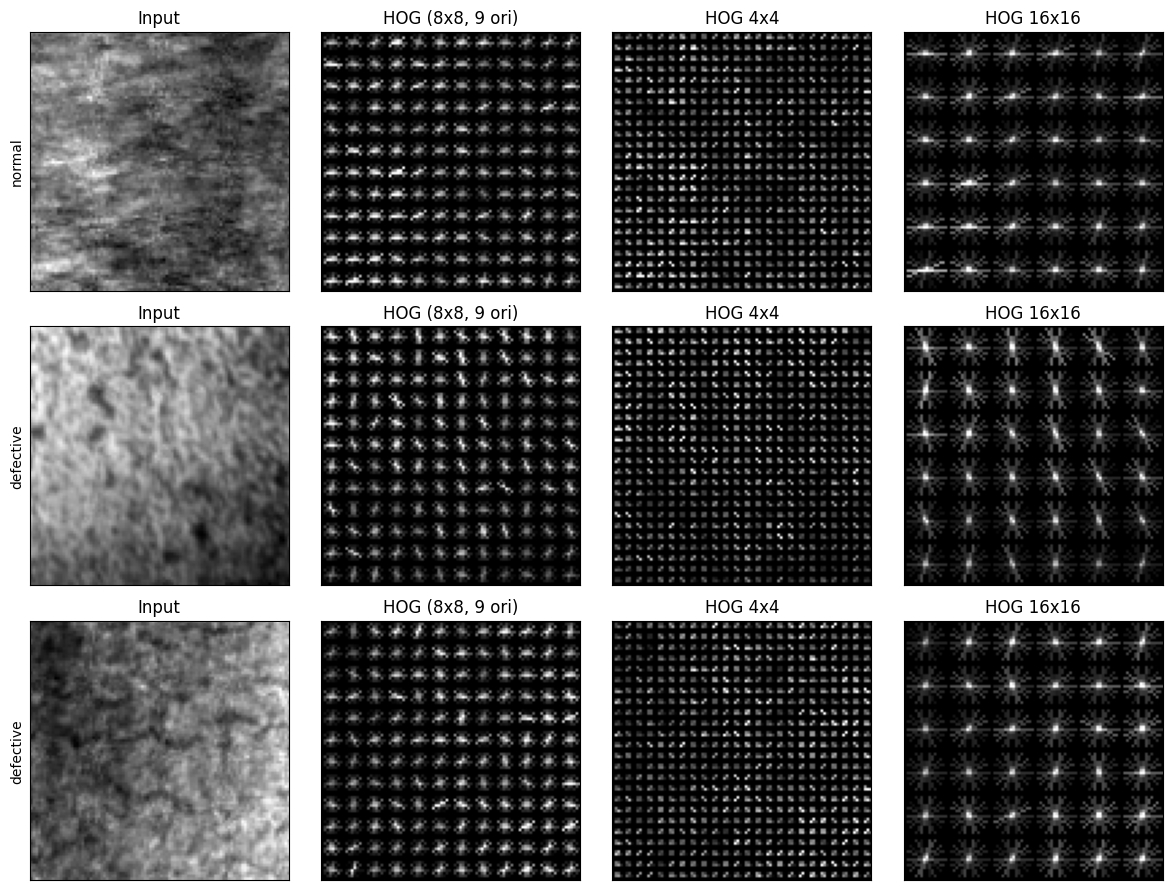

In [7]:
def hog_feat(img, cell=DEF_CELL, ori=DEF_ORI, block=2, visualize=False):
    return hog(img, orientations=ori, pixels_per_cell=(cell, cell),
               cells_per_block=(block, block), block_norm="L2-Hys",
               feature_vector=True, visualize=visualize)

def extract(imgs, cell=DEF_CELL, ori=DEF_ORI):
    f = Parallel(n_jobs=-1)(delayed(hog_feat)(i, cell, ori) for i in imgs)
    return np.array(f, dtype=np.float32)

print("HOG vector length (cell=8, ori=9):", hog_feat(Xtr_img[0]).shape[0])

fig, axs = plt.subplots(3, 4, figsize=(12, 9))
picks = [np.where(ytr == 0)[0][0], np.where(ytr == 1)[0][0], np.where(ytr == 1)[0][5]]
for r, i in enumerate(picks):
    _, vis = hog_feat(Xtr_img[i], visualize=True)
    vis = exposure.rescale_intensity(vis, in_range=(0, np.percentile(vis, 99.5) + 1e-9))
    axs[r, 0].imshow(Xtr_img[i], cmap="gray"); axs[r, 0].set_title("Input")
    axs[r, 1].imshow(vis, cmap="gray");        axs[r, 1].set_title("HOG (8x8, 9 ori)")
    _, v4 = hog_feat(Xtr_img[i], cell=4, visualize=True)
    _, v16 = hog_feat(Xtr_img[i], cell=16, visualize=True)
    axs[r, 2].imshow(exposure.rescale_intensity(v4, in_range=(0, np.percentile(v4, 99.5) + 1e-9)), cmap="gray"); axs[r, 2].set_title("HOG 4x4")
    axs[r, 3].imshow(exposure.rescale_intensity(v16, in_range=(0, np.percentile(v16, 99.5) + 1e-9)), cmap="gray"); axs[r, 3].set_title("HOG 16x16")
    axs[r, 0].set_ylabel("normal" if ytr[i] == 0 else "defective")
for a in axs.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Train and compare classifiers (Tasks 6 – 10)
Baseline HOG parameters (cell 8×8, 9 orientations). Models: **SVM (RBF)**, **Random Forest**, **KNN**.

HOG + SVM (RBF)  (fit+predict 31.9s)
               precision    recall  f1-score   support

Non-defective     0.8478    0.4483    0.5865        87
    Defective     0.8457    0.9741    0.9053       270

     accuracy                         0.8459       357
    macro avg     0.8467    0.7112    0.7459       357
 weighted avg     0.8462    0.8459    0.8276       357

HOG + Random Forest  (fit+predict 28.4s)
               precision    recall  f1-score   support

Non-defective     1.0000    0.1609    0.2772        87
    Defective     0.7872    1.0000    0.8809       270

     accuracy                         0.7955       357
    macro avg     0.8936    0.5805    0.5791       357
 weighted avg     0.8390    0.7955    0.7338       357

HOG + KNN  (fit+predict 0.3s)
               precision    recall  f1-score   support

Non-defective     0.3498    0.8966    0.5032        87
    Defective     0.9328    0.4630    0.6188       270

     accuracy                         0.5686       357
    

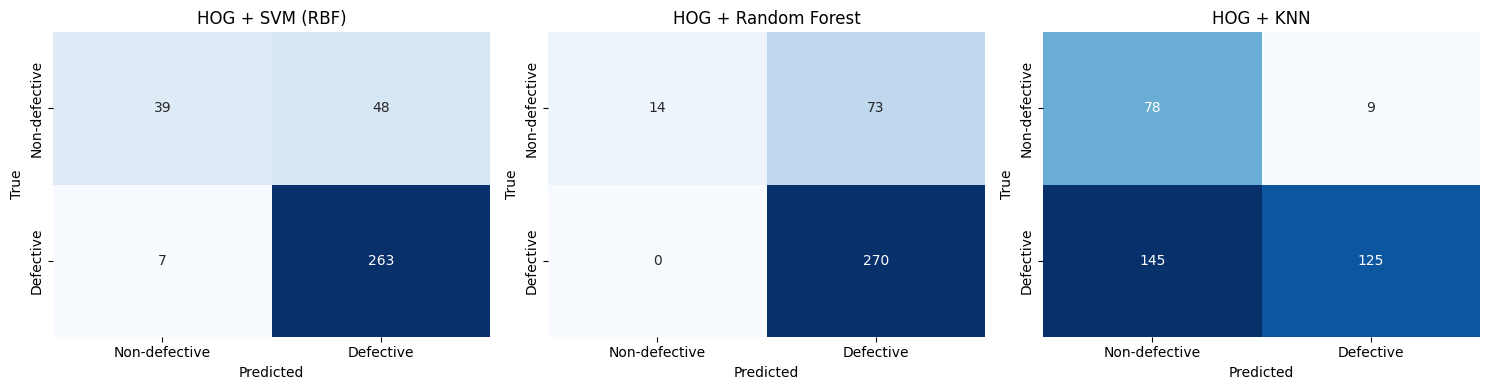

,Accuracy,Precision,Recall,F1
HOG + SVM (RBF),0.8459,0.8457,0.9741,0.9053
HOG + Random Forest,0.7955,0.7872,1.0000,0.8809
HOG + KNN,0.5686,0.9328,0.4630,0.6188


In [8]:
def metrics(yt, yp, avg="binary"):
    return dict(Accuracy=accuracy_score(yt, yp),
                Precision=precision_score(yt, yp, average=avg, zero_division=0),
                Recall=recall_score(yt, yp, average=avg, zero_division=0),
                F1=f1_score(yt, yp, average=avg, zero_division=0))

def get_models():
    return {
        "HOG + SVM (RBF)": make_pipeline(StandardScaler(),
                SVC(kernel="rbf", C=10, gamma="scale", probability=True,
                    class_weight="balanced", random_state=SEED)),
        "HOG + Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1,
                    class_weight="balanced", random_state=SEED),
        "HOG + KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    }

def plot_cm(cm, labels, ax, title):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)

Ftr, Fte = extract(Xtr_img), extract(Xte_img)
names = ["Non-defective", "Defective"]
base_res, fig_axs = {}, plt.subplots(1, 3, figsize=(15, 4))[1]
for ax, (n, m) in zip(fig_axs, get_models().items()):
    t = time.time(); m.fit(Ftr, ytr); yp = m.predict(Fte)
    base_res[n] = metrics(yte, yp)
    print("=" * 60, f"\n{n}  (fit+predict {time.time() - t:.1f}s)")
    print(classification_report(yte, yp, target_names=names, digits=4))
    plot_cm(confusion_matrix(yte, yp), names, ax, n)
plt.tight_layout(); plt.show()
display(pd.DataFrame(base_res).T.round(4))

## 5. Effect of HOG parameters (Task 11)
Cell sizes **4, 8, 16** × orientations **6, 9, 12** with an SVM.
The best combination is selected on the **validation** set (the test set stays untouched).

cell  4 | ori  6 | feats  12696 | F1 0.9060 | acc 0.8468
cell  4 | ori  9 | feats  19044 | F1 0.8896 | acc 0.8162
cell  4 | ori 12 | feats  25392 | F1 0.8968 | acc 0.8301
cell  8 | ori  6 | feats   2904 | F1 0.9078 | acc 0.8524
cell  8 | ori  9 | feats   4356 | F1 0.9047 | acc 0.8468
cell  8 | ori 12 | feats   5808 | F1 0.9236 | acc 0.8774
cell 16 | ori  6 | feats    600 | F1 0.8969 | acc 0.8412
cell 16 | ori  9 | feats    900 | F1 0.9036 | acc 0.8496
cell 16 | ori 12 | feats   1200 | F1 0.8897 | acc 0.8273


,cell,orientations,features,time_s,Accuracy,Precision,Recall,F1
0,4x4,6,12696,56.3,0.8468,0.8439,0.9779,0.9060
1,4x4,9,19044,79.7,0.8162,0.8135,0.9815,0.8896
2,4x4,12,25392,101.7,0.8301,0.8281,0.9779,0.8968
3,8x8,6,2904,12.0,0.8524,0.8586,0.9631,0.9078
4,8x8,9,4356,15.4,0.8468,0.8529,0.9631,0.9047
5,8x8,12,5808,19.8,0.8774,0.8721,0.9815,0.9236
6,16x16,6,600,3.3,0.8412,0.8794,0.9151,0.8969
7,16x16,9,900,3.8,0.8496,0.8754,0.9336,0.9036
8,16x16,12,1200,5.7,0.8273,0.8591,0.9225,0.8897


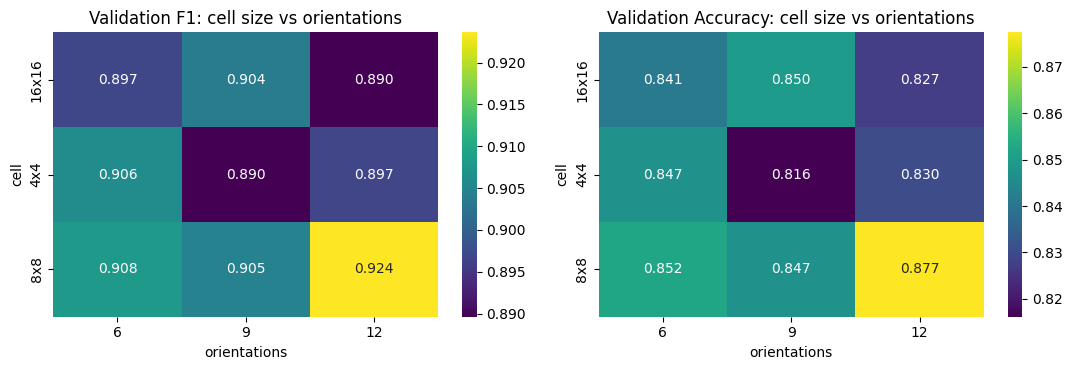

Best HOG parameters -> cell 8x8, orientations 12


In [9]:
rows = []
for cell in (4, 8, 16):
    for ori in (6, 9, 12):
        t = time.time()
        A, B = extract(Xtr_img, cell, ori), extract(Xva_img, cell, ori)
        svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale",
                                                  class_weight="balanced", random_state=SEED))
        svm.fit(A, ytr); m = metrics(yva, svm.predict(B))
        rows.append(dict(cell=f"{cell}x{cell}", orientations=ori, features=A.shape[1],
                         time_s=round(time.time() - t, 1), **m))
        print(f"cell {cell:2d} | ori {ori:2d} | feats {A.shape[1]:6d} | F1 {m['F1']:.4f} | acc {m['Accuracy']:.4f}")
grid = pd.DataFrame(rows)
display(grid.round(4))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, met in zip(axs, ["F1", "Accuracy"]):
    sns.heatmap(grid.pivot(index="cell", columns="orientations", values=met),
                annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"Validation {met}: cell size vs orientations")
plt.tight_layout(); plt.show()

best = grid.sort_values(["F1", "Accuracy"], ascending=False).iloc[0]
BEST_CELL, BEST_ORI = int(best.cell.split("x")[0]), int(best.orientations)
print(f"Best HOG parameters -> cell {BEST_CELL}x{BEST_CELL}, orientations {BEST_ORI}")

## 6. Final models with best HOG parameters (Tasks 7, 8, 9, 10)
Models are retrained on train + validation and evaluated once on the untouched test set.

HOG + SVM (RBF)
               precision    recall  f1-score   support

Non-defective     0.7551    0.4253    0.5441        87
    Defective     0.8377    0.9556    0.8927       270

     accuracy                         0.8263       357
    macro avg     0.7964    0.6904    0.7184       357
 weighted avg     0.8175    0.8263    0.8078       357

HOG + Random Forest
               precision    recall  f1-score   support

Non-defective     0.9583    0.2644    0.4144        87
    Defective     0.8078    0.9963    0.8922       270

     accuracy                         0.8179       357
    macro avg     0.8831    0.6303    0.6533       357
 weighted avg     0.8445    0.8179    0.7758       357

HOG + KNN
               precision    recall  f1-score   support

Non-defective     0.3793    0.8851    0.5310        87
    Defective     0.9351    0.5333    0.6792       270

     accuracy                         0.6190       357
    macro avg     0.6572    0.7092    0.6051       357
 weighted a

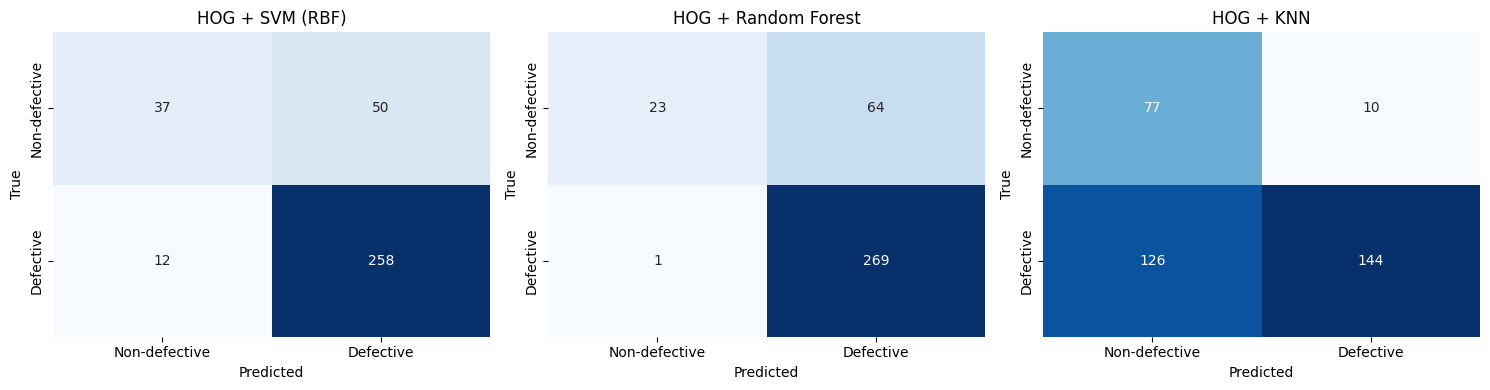

,Accuracy,Precision,Recall,F1
HOG + SVM (RBF),0.8263,0.8377,0.9556,0.8927
HOG + Random Forest,0.8179,0.8078,0.9963,0.8922
HOG + KNN,0.6190,0.9351,0.5333,0.6792


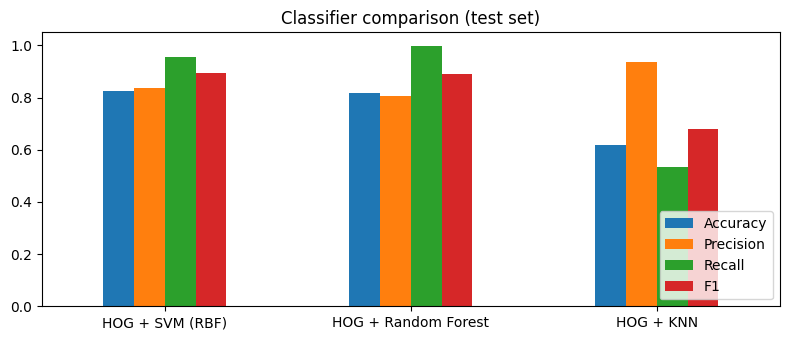

Selected model for deployment: HOG + SVM (RBF)


In [10]:
Xtv_img = np.concatenate([Xtr_img, Xva_img]); ytv = np.concatenate([ytr, yva])
Ftv  = extract(Xtv_img, BEST_CELL, BEST_ORI)
Fte2 = extract(Xte_img, BEST_CELL, BEST_ORI)

final_models, final_res = {}, {}
axs = plt.subplots(1, 3, figsize=(15, 4))[1]
for ax, (n, m) in zip(axs, get_models().items()):
    m.fit(Ftv, ytv); yp = m.predict(Fte2)
    final_models[n] = m; final_res[n] = metrics(yte, yp)
    print("=" * 60, "\n" + n); print(classification_report(yte, yp, target_names=names, digits=4))
    plot_cm(confusion_matrix(yte, yp), names, ax, n)
plt.tight_layout(); plt.show()

res_df = pd.DataFrame(final_res).T.round(4); display(res_df)
res_df.plot(kind="bar", figsize=(8, 3.5), ylim=(0, 1.05)); plt.title("Classifier comparison (test set)")
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

FINAL_NAME  = res_df["F1"].idxmax()
FINAL_MODEL = final_models[FINAL_NAME]
print("Selected model for deployment:", FINAL_NAME)

## 7. Robustness analysis (Task 12)
The trained model is tested on perturbed test images: **brightness, Gaussian noise, rotation, blur**.

,Condition,Accuracy,Precision,Recall,F1,dAccuracy,dF1
0,Clean,0.8263,0.8377,0.9556,0.8927,0.0000,0.0000
1,Brightness x0.6,0.7927,0.8798,0.8407,0.8598,-0.0336,-0.0329
2,Brightness x1.4,0.8347,0.8328,0.9778,0.8995,0.0084,0.0068
3,Noise sigma=10,0.7507,0.7638,0.9704,0.8548,-0.0756,-0.0379
4,Noise sigma=25,0.7563,0.7563,1.0000,0.8612,-0.0700,-0.0315
5,Rotation 10 deg,0.8543,0.8428,0.9926,0.9116,0.0280,0.0188
6,Rotation 30 deg,0.8319,0.8302,0.9778,0.8980,0.0056,0.0052
7,Blur k=5,0.7647,0.7642,0.9963,0.8650,-0.0616,-0.0278
8,Blur k=9,0.7563,0.7563,1.0000,0.8612,-0.0700,-0.0315


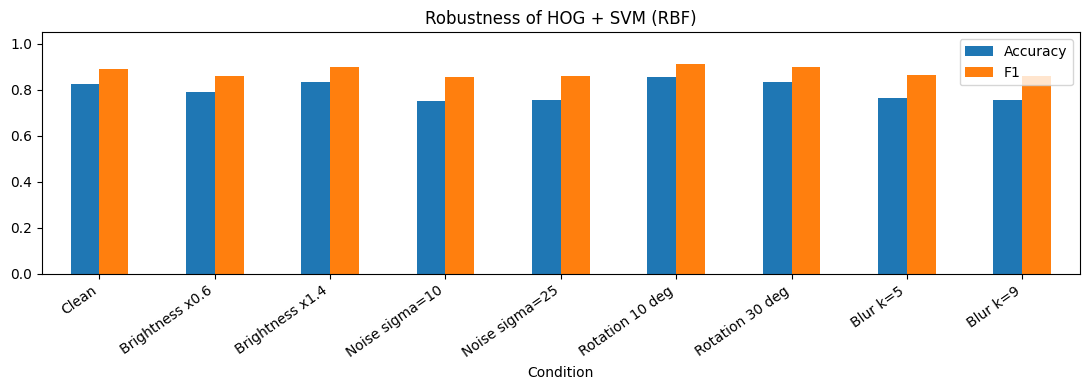

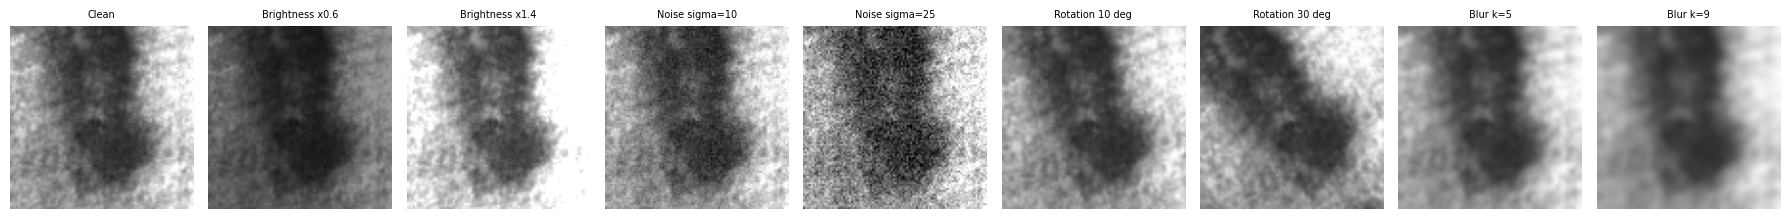

In [11]:
def brightness(img, f): return np.clip(img.astype(np.float32) * f, 0, 255).astype(np.uint8)
def noise(img, s, seed=0):
    r = np.random.default_rng(seed)
    return np.clip(img.astype(np.float32) + r.normal(0, s, img.shape), 0, 255).astype(np.uint8)
def rotate(img, a):
    h, w = img.shape; M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
def blur(img, k): return cv2.GaussianBlur(img, (k, k), 0)

conds = {
    "Clean": lambda i: i,
    "Brightness x0.6": lambda i: brightness(i, 0.6),
    "Brightness x1.4": lambda i: brightness(i, 1.4),
    "Noise sigma=10": lambda i: noise(i, 10),
    "Noise sigma=25": lambda i: noise(i, 25),
    "Rotation 10 deg": lambda i: rotate(i, 10),
    "Rotation 30 deg": lambda i: rotate(i, 30),
    "Blur k=5": lambda i: blur(i, 5),
    "Blur k=9": lambda i: blur(i, 9),
}
rob = []
for n, fn in conds.items():
    imgs = np.array([fn(i) for i in Xte_img])
    yp = FINAL_MODEL.predict(extract(imgs, BEST_CELL, BEST_ORI))
    rob.append(dict(Condition=n, **metrics(yte, yp)))
rob = pd.DataFrame(rob)
rob["dAccuracy"] = rob.Accuracy - rob.Accuracy.iloc[0]
rob["dF1"] = rob.F1 - rob.F1.iloc[0]
display(rob.round(4))

rob.set_index("Condition")[["Accuracy", "F1"]].plot(kind="bar", figsize=(11, 4), ylim=(0, 1.05))
plt.title(f"Robustness of {FINAL_NAME}"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

# visual examples
i0 = int(np.where(yte == 1)[0][0])
fig, axs = plt.subplots(1, len(conds), figsize=(2 * len(conds), 2.3))
for ax, (n, fn) in zip(axs, conds.items()):
    ax.imshow(fn(Xte_img[i0]), cmap="gray", vmin=0, vmax=255); ax.set_title(n, fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Industrial quality-control decision module (Task 13)
Large images (for example the full 200×200 steel image) are inspected in tiles. If **any** tile is defective, the product is **rejected**.

---- one normal crop ----
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 68.3%
Action: REJECT PRODUCT


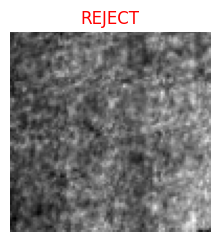


---- one defective crop ----
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 81.8%
Action: REJECT PRODUCT


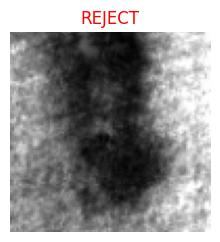


---- full test image (tile-based) ----
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 89.8%
Action: REJECT PRODUCT


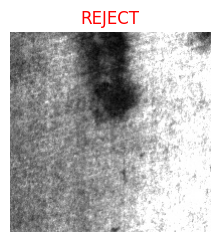

(True, 89.756651413528)

In [12]:
def defect_probability(gray, model=None, cell=None, ori=None):
    model = model or FINAL_MODEL; cell = cell or BEST_CELL; ori = ori or BEST_ORI
    H, W = gray.shape
    if H <= CROP and W <= CROP:
        tiles = [gray]
    else:
        tiles = [gray[y:y + CROP, x:x + CROP]
                 for y in range(0, H - CROP + 1, CROP) for x in range(0, W - CROP + 1, CROP)]
    f = np.array([hog_feat(prep(t), cell, ori) for t in tiles], dtype=np.float32)
    p = model.predict_proba(f)[:, list(model.classes_).index(1)]
    return float(p.max())

def inspect_product(image, threshold=0.5, show=True):
    gray = load_gray(image) if isinstance(image, str) else (
        cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image)
    p_def = defect_probability(gray)
    defective = p_def >= threshold
    conf = (p_def if defective else 1 - p_def) * 100
    print("PRODUCT INSPECTION RESULT")
    print(f"Prediction: {'DEFECTIVE' if defective else 'NON-DEFECTIVE'}")
    print(f"Confidence: {conf:.1f}%")
    print(f"Action: {'REJECT PRODUCT' if defective else 'ACCEPT PRODUCT'}")
    if show:
        plt.figure(figsize=(2.6, 2.6)); plt.imshow(gray, cmap="gray"); plt.axis("off")
        plt.title("REJECT" if defective else "ACCEPT", color="red" if defective else "green"); plt.show()
    return defective, conf

print("---- one normal crop ----");    inspect_product(Xte_img[int(np.where(yte == 0)[0][0])])
print("\n---- one defective crop ----"); inspect_product(Xte_img[int(np.where(yte == 1)[0][0])])
print("\n---- full test image (tile-based) ----"); inspect_product(p_test[0])

## 9. Advanced: multi-class defect classification (6 defect types)
Full images are resized to 128×128 and classified with HOG + SVM and HOG + Random Forest.

HOG + SVM (RBF)
                 precision    recall  f1-score   support

        crazing     0.8824    1.0000    0.9375        45
      inclusion     0.8039    0.9111    0.8542        45
        patches     0.8462    0.7333    0.7857        45
 pitted_surface     0.8043    0.8222    0.8132        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     0.9474    0.8000    0.8675        45

       accuracy                         0.8778       270
      macro avg     0.8807    0.8778    0.8763       270
   weighted avg     0.8807    0.8778    0.8763       270

HOG + Random Forest
                 precision    recall  f1-score   support

        crazing     0.7143    1.0000    0.8333        45
      inclusion     0.7500    0.9333    0.8317        45
        patches     0.9333    0.6222    0.7467        45
 pitted_surface     0.7561    0.6889    0.7209        45
rolled-in_scale     0.9375    1.0000    0.9677        45
      scratches     0.9688    0.6889    0.8052  

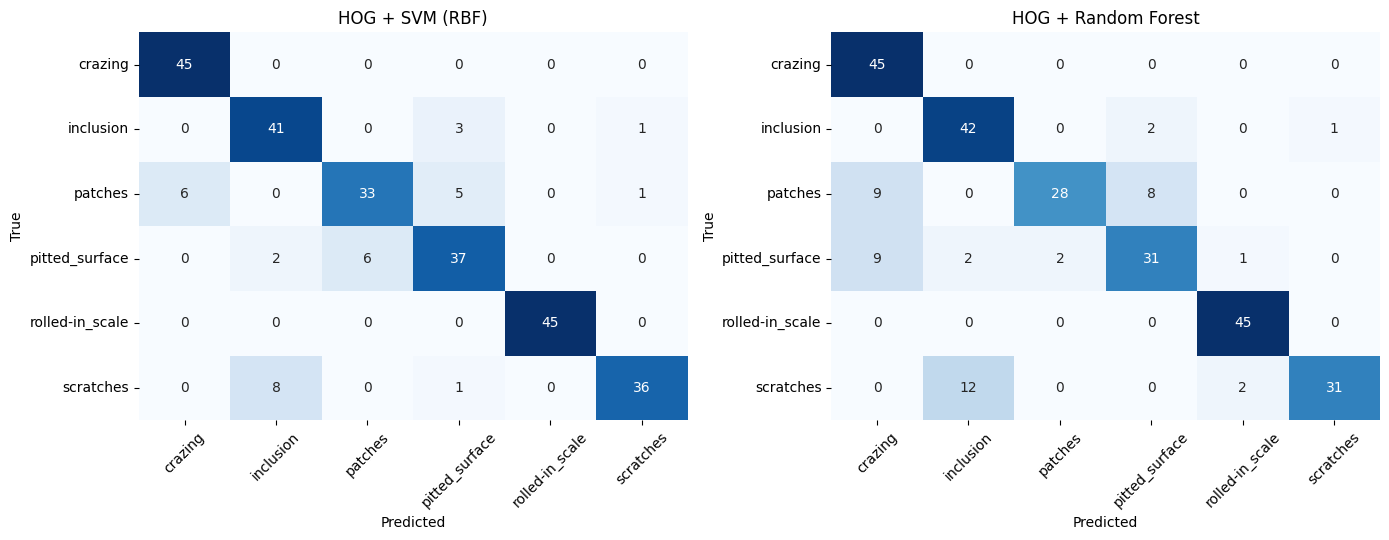

,Accuracy,Precision,Recall,F1
HOG + SVM (RBF),0.8778,0.8807,0.8778,0.8763
HOG + Random Forest,0.8222,0.8433,0.8222,0.8176


In [13]:
MC_SIZE = 128
def load_mc(paths):
    X = np.array([prep(load_gray(p), MC_SIZE) for p in paths]); y = np.array([lab[p] for p in paths]); return X, y
Xm_tv, ym_tv = load_mc(np.concatenate([p_train, p_val])); Xm_te, ym_te = load_mc(p_test)

Fm_tv = np.array(Parallel(n_jobs=-1)(delayed(hog_feat)(i, BEST_CELL, BEST_ORI) for i in Xm_tv), np.float32)
Fm_te = np.array(Parallel(n_jobs=-1)(delayed(hog_feat)(i, BEST_CELL, BEST_ORI) for i in Xm_te), np.float32)

mc_models = {
    "HOG + SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)),
    "HOG + Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
}
mc_res = {}; mc_labels = sorted(set(ym_tv))
axs = plt.subplots(1, 2, figsize=(14, 5.5))[1]
for ax, (n, m) in zip(axs, mc_models.items()):
    m.fit(Fm_tv, ym_tv); yp = m.predict(Fm_te); mc_res[n] = metrics(ym_te, yp, "macro")
    print("=" * 60, "\n" + n); print(classification_report(ym_te, yp, digits=4))
    plot_cm(confusion_matrix(ym_te, yp, labels=mc_labels), mc_labels, ax, n)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
display(pd.DataFrame(mc_res).T.round(4))

## 10. Save the model

In [14]:
joblib.dump({"model": FINAL_MODEL, "cell": BEST_CELL, "orientations": BEST_ORI,
             "img_size": IMG_SIZE, "crop": CROP, "name": FINAL_NAME}, "hog_defect_model.joblib")
print("Saved: hog_defect_model.joblib")

Saved: hog_defect_model.joblib


## 11. Bonus: real-time prototype (webcam / video stream)
`cv2.imshow` does not work inside Google Colab. Run this on a **local Jupyter** with a webcam (`source=0`), or pass a **video file path** as `source`.

In [15]:
def realtime_inspection(source=0, threshold=0.5, max_frames=None):
    cap = cv2.VideoCapture(source)
    if not cap.isOpened():
        print("Cannot open video source."); return
    n = 0
    while True:
        ok, frame = cap.read()
        if not ok or (max_frames and n >= max_frames): break
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        p = defect_probability(gray)                      # HOG features extracted from each frame
        bad = p >= threshold
        label = f"{'DEFECTIVE' if bad else 'PASS'} ({(p if bad else 1 - p) * 100:.0f}%)"
        cv2.putText(frame, label, (15, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0,
                    (0, 0, 255) if bad else (0, 200, 0), 2)
        cv2.imshow("HOG Inspection (press q to quit)", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"): break
        n += 1
    cap.release(); cv2.destroyAllWindows()

# realtime_inspection(0)                    # webcam
# realtime_inspection("path/to/video.mp4")  # video file

## Notes for the report
* Use the tables from sections 4–7 for **Results** and **Robustness Analysis**.
* **Limitations:** NEU-DET has no real defect-free images, so "normal" crops are defect-free regions of defective steel surfaces; HOG is not rotation invariant; results come from a small dataset.